# Health Tracking — Trends & Cross-Domain Insights

Loads `health_log.xlsx` (Food, Activities, Sleep), cleans it, then explores trends over time and relationships between domains.

Re-run top-to-bottom after each Excel update.

## Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)

from loader import load_all, refresh_local_copy

# Try to pull a fresh copy from OneDrive (skipped silently if Excel is open)
refreshed = refresh_local_copy()
print(f'Refreshed from OneDrive: {refreshed}')

Refreshed from OneDrive: True


## Load data

In [2]:
data = load_all()
food, activities, sleep = data['food'], data['activities'], data['sleep']

summary = pd.DataFrame(
    {
        'rows': [len(food), len(activities), len(sleep)],
        'first_date': [food['Date'].min(), activities['Date'].min(), sleep['Date'].min()],
        'last_date':  [food['Date'].max(), activities['Date'].max(), sleep['Date'].max()],
    },
    index=['food', 'activities', 'sleep'],
)
summary

,rows,first_date,last_date
food,10,2026-05-09 00:00:00,2026-05-18 00:00:00
activities,20,2026-04-02 17:52:49,2026-05-17 18:26:30
sleep,37,2026-04-13 00:00:00,2026-05-19 00:00:00


## 1. Sleep — trends over time

Sleep is the densest dataset, so it gets the most attention. We plot each headline metric with a 7-day rolling mean to smooth night-to-night noise.

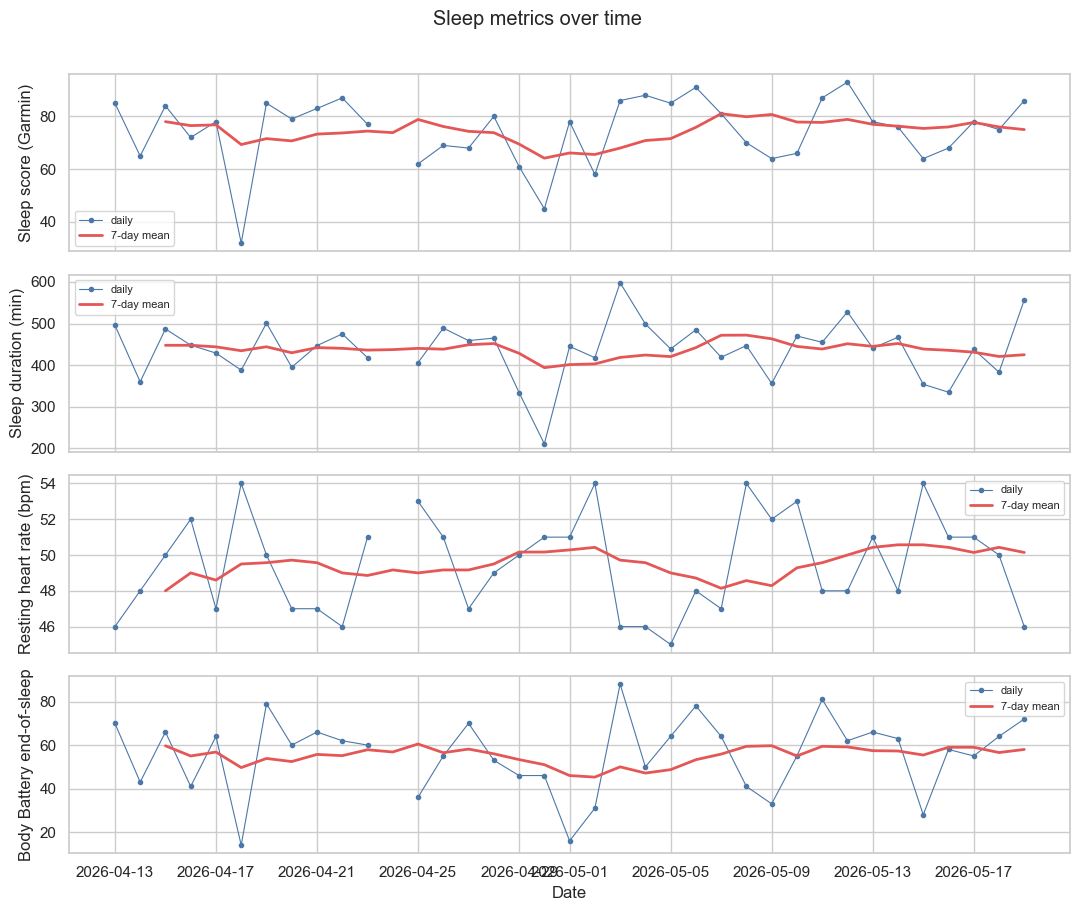

In [3]:
metrics = [
    ('Score',              'Sleep score (Garmin)'),
    ('duration_min',       'Sleep duration (min)'),
    ('Resting Heart Rate', 'Resting heart rate (bpm)'),
    ('Body Battery',       'Body Battery end-of-sleep'),
]
fig, axes = plt.subplots(len(metrics), 1, figsize=(11, 9), sharex=True)
for ax, (col, label) in zip(axes, metrics):
    s = sleep.set_index('Date')[col].astype(float)
    ax.plot(s.index, s.values, marker='o', ms=3, lw=0.8, color='#4c78a8', label='daily')
    ax.plot(s.index, s.rolling(7, min_periods=3).mean(), color='#e45756', lw=2, label='7-day mean')
    ax.set_ylabel(label)
    ax.legend(loc='best', fontsize=8)
axes[-1].set_xlabel('Date')
fig.suptitle('Sleep metrics over time', y=1.01)
fig.tight_layout()
plt.show()

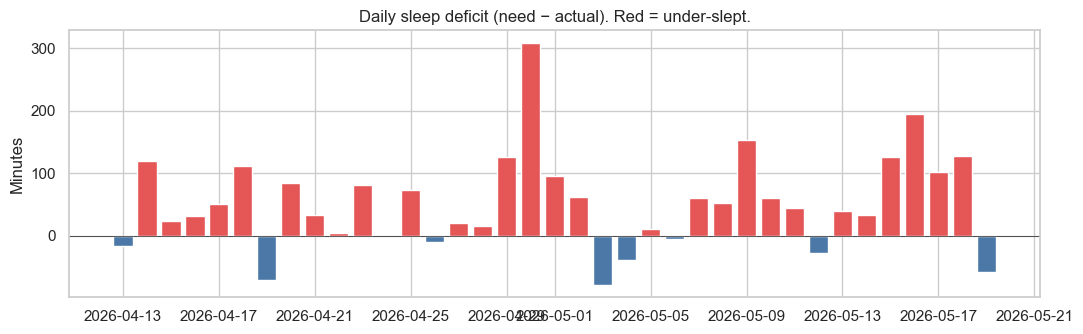

Under-slept on 76% of nights | mean deficit +54 min


In [4]:
# Sleep deficit: need minus actual. Positive = under-slept vs body's stated need.
fig, ax = plt.subplots(figsize=(11, 3.5))
colors = sleep['sleep_deficit_min'].apply(lambda x: '#e45756' if x > 0 else '#4c78a8')
ax.bar(sleep['Date'], sleep['sleep_deficit_min'], color=colors, width=0.8)
ax.axhline(0, color='k', lw=0.5)
ax.set_title('Daily sleep deficit (need − actual). Red = under-slept.')
ax.set_ylabel('Minutes')
fig.tight_layout()
plt.show()

deficit_stats = sleep['sleep_deficit_min'].describe()
under_slept_pct = (sleep['sleep_deficit_min'] > 0).mean() * 100
print(f'Under-slept on {under_slept_pct:.0f}% of nights | mean deficit {deficit_stats["mean"]:+.0f} min')

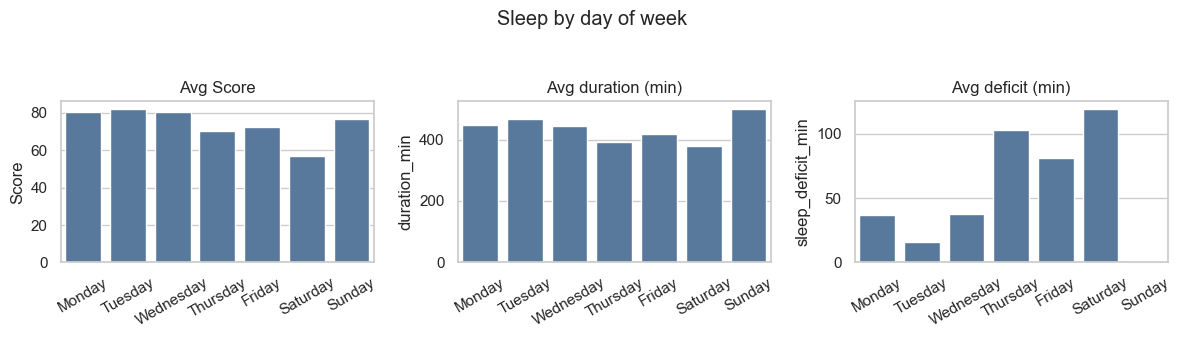

,Score,duration_min,sleep_deficit_min
dow,,,
Monday,80.3,447.8,37.2
Tuesday,82.0,466.0,15.7
Wednesday,80.2,444.4,37.6
Thursday,70.2,392.6,103.4
Friday,72.5,418.8,81.2
Saturday,56.8,380.6,119.4
Sunday,76.8,499.2,0.8


In [5]:
# Day-of-week patterns
sleep_dow = sleep.assign(dow=sleep['Date'].dt.day_name())
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
agg = sleep_dow.groupby('dow')[['Score','duration_min','sleep_deficit_min']].mean().reindex(order)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, ttl in zip(axes, ['Score','duration_min','sleep_deficit_min'],
                       ['Avg Score','Avg duration (min)','Avg deficit (min)']):
    sns.barplot(x=agg.index, y=agg[col], ax=ax, color='#4c78a8')
    ax.set_title(ttl)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
fig.suptitle('Sleep by day of week', y=1.05)
fig.tight_layout()
plt.show()
agg.round(1)

## 2. Activities — cadence & intensity

Weekly volume, intensity (HR + calories), and run-pace progression.

In [6]:
weekly = (
    activities.assign(week=activities['Date'].dt.to_period('W').dt.start_time)
    .groupby('week')
    .agg(sessions=('Date','count'),
         total_min=('duration_min','sum'),
         total_distance_km=('Distance','sum'),
         total_calories=('Calories','sum'),
         avg_HR=('Avg HR','mean'))
    .round(1)
)
weekly

,sessions,total_min,total_distance_km,total_calories,avg_HR
week,,,,,
2026-03-30,2,60.6,6.6,756,151.5
2026-04-06,4,485.0,42.0,2227,103.0
2026-04-13,2,46.6,6.0,559,141.5
2026-04-20,3,166.5,21.6,1519,138.0
2026-04-27,1,30.1,5.2,386,157.0
2026-05-04,5,169.2,22.7,2182,156.2
2026-05-11,3,101.4,11.5,1342,148.7


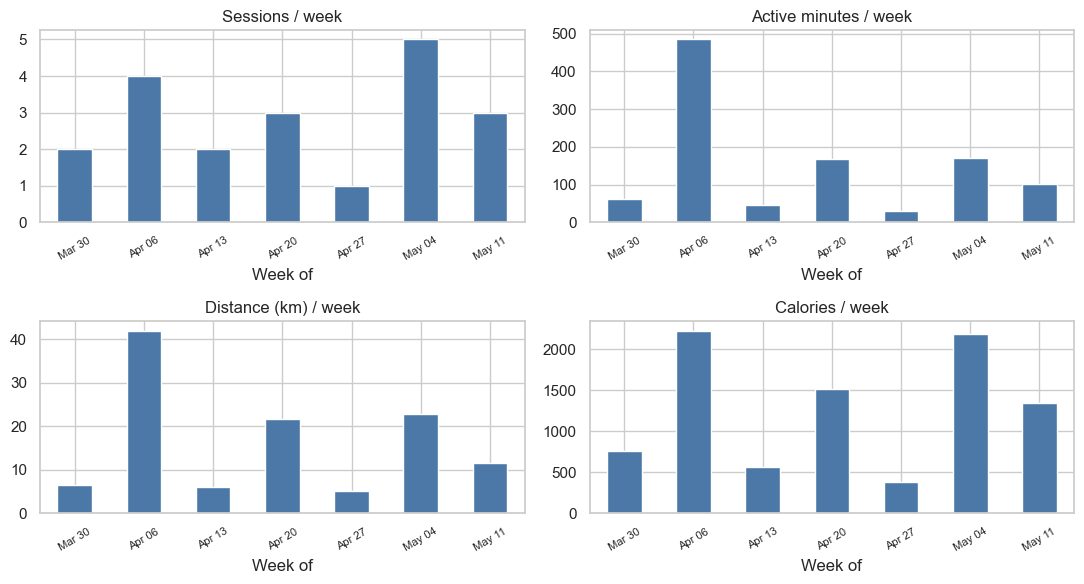

In [7]:
weekly_plot = weekly.copy()
weekly_plot.index = [d.strftime('%b %d') for d in weekly_plot.index]
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
weekly_plot['sessions'].plot.bar(ax=axes[0,0], color='#4c78a8', title='Sessions / week')
weekly_plot['total_min'].plot.bar(ax=axes[0,1], color='#4c78a8', title='Active minutes / week')
weekly_plot['total_distance_km'].plot.bar(ax=axes[1,0], color='#4c78a8', title='Distance (km) / week')
weekly_plot['total_calories'].plot.bar(ax=axes[1,1], color='#4c78a8', title='Calories / week')
for ax in axes.ravel():
    ax.set_xlabel('Week of')
    ax.tick_params(axis='x', rotation=30, labelsize=8)
fig.tight_layout()
plt.show()

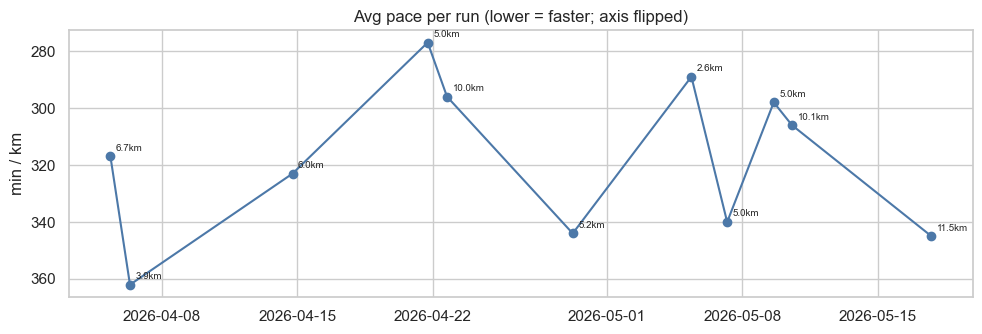

,Date,Title,Distance,duration_min,avg_pace_min_per_km,Avg HR,Calories
0,2026-04-05 08:02:21,Nashville Running,6.65,35.116667,317.0,155,464
1,2026-04-06 08:17:07,Nashville Running,3.89,23.433333,362.0,157,303
2,2026-04-14 17:56:28,Appleton Running,6.03,32.466667,323.0,163,449
3,2026-04-21 17:32:13,Treadmill Running,5.02,23.166667,277.0,140,247
4,2026-04-22 17:31:38,Paris Running,10.02,49.400000,296.0,174,711
5,2026-04-29 05:26:46,Treadmill Running,5.25,30.066667,344.0,157,386
6,2026-05-05 08:39:13,Lambeth Running,2.65,12.766667,289.0,160,176
7,2026-05-07 05:00:26,Treadmill Running,5.00,28.333333,340.0,129,248
8,2026-05-09 14:45:58,Chicago Running,5.00,24.800000,298.0,169,358
9,2026-05-10 13:21:28,Chicago Running,10.05,51.233333,306.0,164,719


In [8]:
# Run-pace progression (only Running / Treadmill Running)
runs = activities[activities['Activity Type'].isin(['Running','Treadmill Running'])]\
          .dropna(subset=['avg_pace_min_per_km']).sort_values('Date')
if len(runs) >= 2:
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(runs['Date'], runs['avg_pace_min_per_km'], marker='o', color='#4c78a8')
    ax.invert_yaxis()  # faster = lower number, but visually 'up'
    ax.set_title('Avg pace per run (lower = faster; axis flipped)')
    ax.set_ylabel('min / km')
    for _, r in runs.iterrows():
        ax.annotate(f"{r['Distance']:.1f}km", (r['Date'], r['avg_pace_min_per_km']),
                    fontsize=7, xytext=(4, 4), textcoords='offset points')
    fig.tight_layout()
    plt.show()
else:
    print('Not enough run pace data yet.')
runs[['Date','Title','Distance','duration_min','avg_pace_min_per_km','Avg HR','Calories']].reset_index(drop=True)

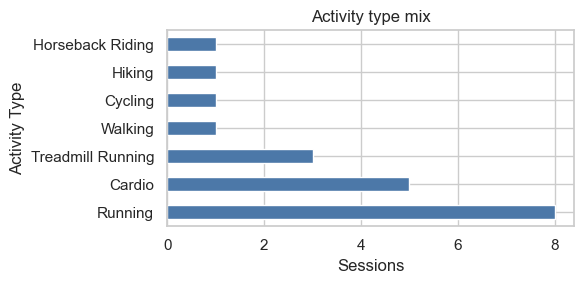

Activity Type
Running              8
Cardio               5
Treadmill Running    3
Walking              1
Cycling              1
Hiking               1
Horseback Riding     1
Name: count, dtype: int64

In [9]:
type_mix = activities['Activity Type'].value_counts()
fig, ax = plt.subplots(figsize=(6, 3))
type_mix.plot.barh(ax=ax, color='#4c78a8')
ax.set_title('Activity type mix')
ax.set_xlabel('Sessions')
fig.tight_layout()
plt.show()
type_mix

## 3. Food — patterns

Food log is the newest input so the sample is small. We focus on Day Rating and behavioural flags (alcohol, skipped breakfast).

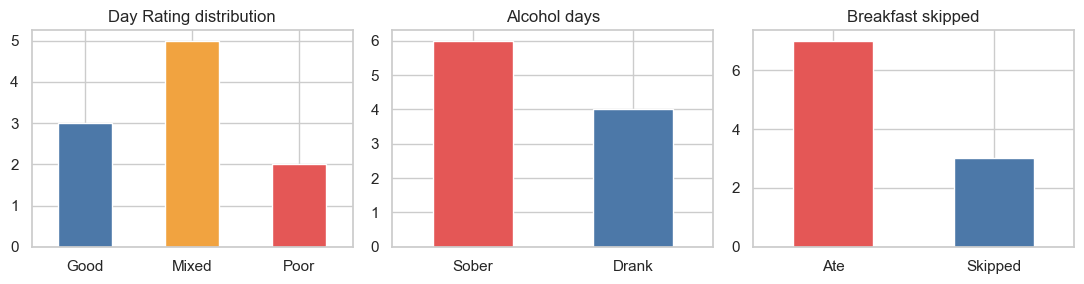

,Date,Day Rating,had_alcohol,skipped_breakfast
0,2026-05-09,Poor,True,False
1,2026-05-10,Mixed,False,False
2,2026-05-11,Mixed,False,True
3,2026-05-12,Good,False,True
4,2026-05-13,Good,False,True
5,2026-05-14,Mixed,True,False
6,2026-05-15,Poor,True,False
7,2026-05-16,Mixed,True,False
8,2026-05-17,Good,False,False
9,2026-05-18,Mixed,False,False


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
food['Day Rating'].value_counts().reindex(['Good','Mixed','Poor']).plot.bar(
    ax=axes[0], color=['#4c78a8','#f1a340','#e45756'])
axes[0].set_title('Day Rating distribution')
food['had_alcohol'].value_counts().rename({True:'Drank',False:'Sober'}).plot.bar(
    ax=axes[1], color=['#e45756','#4c78a8'])
axes[1].set_title('Alcohol days')
food['skipped_breakfast'].value_counts().rename({True:'Skipped',False:'Ate'}).plot.bar(
    ax=axes[2], color=['#e45756','#4c78a8'])
axes[2].set_title('Breakfast skipped')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
plt.show()

food[['Date','Day Rating','had_alcohol','skipped_breakfast']]

## 4. Cross-domain correlations

We build a single daily table (one row per date) joining food, sleep, and the day's activity. Most relationships here are tentative — with ~10 food-logged days, treat anything p > 0.1 as a hypothesis, not a finding.

In [11]:
act_daily = (
    activities.assign(date=activities['Date'].dt.normalize())
    .groupby('date')
    .agg(act_minutes=('duration_min','sum'),
         act_calories=('Calories','sum'),
         act_avg_HR=('Avg HR','mean'),
         act_distance=('Distance','sum'))
)

sleep_daily = sleep.set_index('Date')[
    ['Score','duration_min','Resting Heart Rate','Body Battery','sleep_deficit_min','bedtime_decimal']
].rename(columns={'duration_min':'sleep_min','Resting Heart Rate':'RHR',
                   'Body Battery':'BodyBattery','sleep_deficit_min':'sleep_deficit',
                   'Score':'sleep_score'})

food_daily = food.set_index('Date')[['Day Rating','had_alcohol','skipped_breakfast']]
food_daily['rating_num'] = food_daily['Day Rating'].cat.codes.replace(-1, np.nan)
# rating_num: 0=Good, 1=Mixed, 2=Poor (higher = worse)

daily = sleep_daily.join(act_daily, how='left').join(food_daily, how='left')
daily['exercised'] = daily['act_minutes'].fillna(0) > 0
daily.tail(12)

,sleep_score,sleep_min,RHR,BodyBattery,sleep_deficit,bedtime_decimal,act_minutes,act_calories,act_avg_HR,act_distance,Day Rating,had_alcohol,skipped_breakfast,rating_num,exercised
Date,,,,,,,,,,,,,,,
2026-05-08,70.0,447.0,54.0,41.0,53.0,21.716667,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,False
2026-05-09,64.0,356.0,52.0,33.0,154.0,26.766667,24.800000,358.0,169.0,5.00,Poor,True,False,2.0,True
2026-05-10,66.0,470.0,53.0,55.0,60.0,23.850000,51.233333,719.0,164.0,10.05,Mixed,False,False,1.0,True
2026-05-11,87.0,455.0,48.0,81.0,45.0,22.233333,NaN,NaN,NaN,NaN,Mixed,False,True,1.0,False
2026-05-12,93.0,528.0,48.0,62.0,-28.0,21.650000,24.333333,317.0,155.0,0.00,Good,False,True,0.0,True
2026-05-13,78.0,441.0,51.0,66.0,39.0,22.233333,10.583333,93.0,122.0,0.00,Good,False,True,0.0,True
2026-05-14,76.0,467.0,48.0,63.0,33.0,21.916667,NaN,NaN,NaN,NaN,Mixed,True,False,1.0,False
2026-05-15,64.0,354.0,54.0,28.0,126.0,24.633333,NaN,NaN,NaN,NaN,Poor,True,False,2.0,False
2026-05-16,68.0,335.0,51.0,58.0,195.0,26.133333,NaN,NaN,NaN,NaN,Mixed,True,False,1.0,False


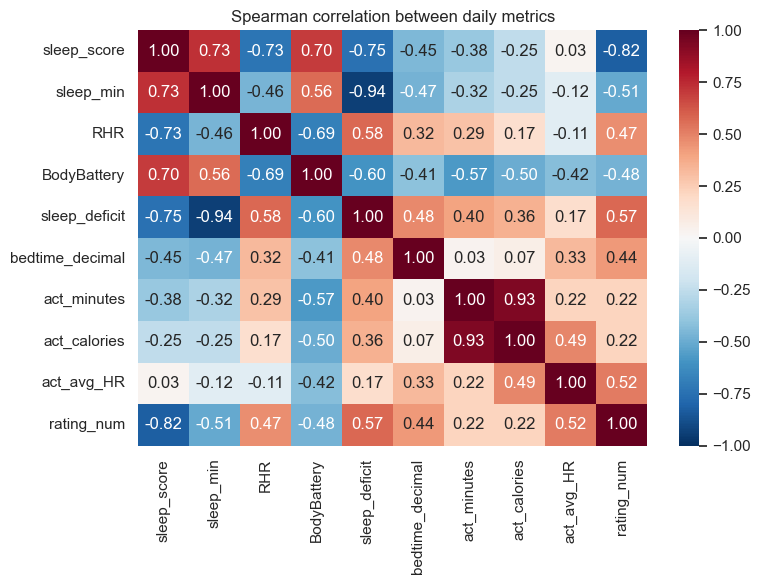

In [12]:
# Heat-map of pairwise correlations on numeric daily columns
num_cols = ['sleep_score','sleep_min','RHR','BodyBattery','sleep_deficit',
            'bedtime_decimal','act_minutes','act_calories','act_avg_HR','rating_num']
corr = daily[num_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Spearman correlation between daily metrics')
fig.tight_layout()
plt.show()

In [13]:
def compare(label_a, mask_a, label_b, mask_b, metric):
    a = daily.loc[mask_a, metric].dropna()
    b = daily.loc[mask_b, metric].dropna()
    if len(a) < 2 or len(b) < 2:
        return {'metric':metric,'n_a':len(a),'n_b':len(b),'mean_a':np.nan,'mean_b':np.nan,'diff':np.nan,'p':np.nan}
    _, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    return {'metric':metric,'n_a':len(a),'n_b':len(b),
            'mean_a':round(a.mean(),1),'mean_b':round(b.mean(),1),
            'diff':round(a.mean()-b.mean(),1),'p':round(p,3)}

# 4a. Alcohol vs sober nights
alc = daily['had_alcohol'] == True
sober = daily['had_alcohol'] == False
alc_vs_sober = pd.DataFrame([
    compare('alcohol', alc, 'sober', sober, m)
    for m in ['sleep_score','sleep_min','RHR','BodyBattery']
])
print('--- Alcohol nights vs sober nights ---')
print(alc_vs_sober.to_string(index=False))

# 4b. Exercise day vs rest day
ex = daily['exercised'] == True
rest = daily['exercised'] == False
ex_vs_rest = pd.DataFrame([
    compare('exercised', ex, 'rest', rest, m)
    for m in ['sleep_score','sleep_min','RHR','BodyBattery']
])
print('\n--- Exercise day vs rest day ---')
print(ex_vs_rest.to_string(index=False))

--- Alcohol nights vs sober nights ---
     metric  n_a  n_b  mean_a  mean_b  diff     p
sleep_score    4    6    68.0    79.5 -11.5 0.068
  sleep_min    4    6   378.0   452.5 -74.5 0.114
        RHR    4    6    51.2    50.2   1.1 0.444
BodyBattery    4    6    45.5    63.8 -18.3 0.165

--- Exercise day vs rest day ---
     metric  n_a  n_b  mean_a  mean_b  diff     p
sleep_score   13   23    75.9    73.8   2.1 0.947
  sleep_min   13   23   430.8   441.0 -10.2 0.500
        RHR   13   23    49.3    49.6  -0.3 0.803
BodyBattery   13   23    55.2    55.7  -0.5 0.856


In [14]:
# 4c. Bedtime impact: late nights (>= 24h decimal, i.e. past midnight) vs early nights
if daily['bedtime_decimal'].notna().sum() >= 6:
    median_bt = daily['bedtime_decimal'].median()
    late = daily['bedtime_decimal'] >= median_bt
    early = daily['bedtime_decimal'] < median_bt
    bt = pd.DataFrame([
        compare(f'late (≥{median_bt:.1f})', late, f'early (<{median_bt:.1f})', early, m)
        for m in ['sleep_score','sleep_min','RHR','BodyBattery']
    ])
    print(f'--- Late bedtime (≥{median_bt:.2f}) vs early ---')
    print(bt.to_string(index=False))

--- Late bedtime (≥22.70) vs early ---
     metric  n_a  n_b  mean_a  mean_b  diff     p
sleep_score   18   18    71.9    77.2  -5.2 0.121
  sleep_min   18   18   415.8   458.8 -43.0 0.058
        RHR   18   18    49.7    49.3   0.4 0.702
BodyBattery   18   18    51.2    59.9  -8.7 0.079


## 5. Auto-generated summary

In [15]:
lines = []
n_sleep = sleep['Score'].notna().sum()
mean_score = sleep['Score'].mean()
trend = stats.linregress(np.arange(len(sleep)), sleep['Score'].fillna(sleep['Score'].mean()))
direction = 'improving' if trend.slope > 0 else 'declining'
lines.append(f'**Sleep:** avg score {mean_score:.1f} over {n_sleep} nights — trend {direction} ({trend.slope:+.2f}/day, p={trend.pvalue:.2f}).')

under = (sleep['sleep_deficit_min'] > 0).sum()
lines.append(f'**Sleep debt:** under-slept on {under}/{n_sleep} nights vs Garmin sleep-need.')

if len(activities):
    span_days = (activities['Date'].max() - activities['Date'].min()).days + 1
    lines.append(f'**Activity cadence:** {len(activities)} sessions over {span_days} days '
                 f'(~{len(activities)/(span_days/7):.1f}/week).')

alc_row = alc_vs_sober.iloc[0]
if pd.notna(alc_row['p']):
    sig = '✓' if alc_row['p'] < 0.1 else '~'
    lines.append(f'**Alcohol → sleep score:** {alc_row["mean_a"]} (n={alc_row["n_a"]}) vs '
                 f'{alc_row["mean_b"]} sober (n={alc_row["n_b"]}) — diff {alc_row["diff"]:+.1f} '
                 f'(p={alc_row["p"]}) {sig}')

ex_row = ex_vs_rest.iloc[0]
if pd.notna(ex_row['p']):
    sig = '✓' if ex_row['p'] < 0.1 else '~'
    lines.append(f'**Exercise → sleep score:** {ex_row["mean_a"]} (n={ex_row["n_a"]}) vs '
                 f'{ex_row["mean_b"]} rest (n={ex_row["n_b"]}) — diff {ex_row["diff"]:+.1f} '
                 f'(p={ex_row["p"]}) {sig}')

# Strongest correlation in matrix (upper triangle only, exclude trivially related pairs)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
c = corr.where(mask)
trivial = {('sleep_min','sleep_deficit'), ('act_minutes','act_calories'),
           ('act_minutes','act_distance'), ('act_calories','act_distance')}
stacked = c.abs().stack().sort_values(ascending=False)
shown = 0
for (a, b), val in stacked.items():
    if tuple(sorted([a, b])) in {tuple(sorted(p)) for p in trivial}:
        continue
    raw = corr.loc[a, b]
    lines.append(f'**Notable correlation:** `{a}` ↔ `{b}` ρ = {raw:+.2f}')
    shown += 1
    if shown >= 4:
        break

from IPython.display import Markdown
Markdown('\n\n'.join(f'- {l}' for l in lines))

- **Sleep:** avg score 74.6 over 36 nights — trend improving (+0.14/day, p=0.50).

- **Sleep debt:** under-slept on 28/36 nights vs Garmin sleep-need.

- **Activity cadence:** 20 sessions over 46 days (~3.0/week).

- **Alcohol → sleep score:** 68.0 (n=4) vs 79.5 sober (n=6) — diff -11.5 (p=0.068) ✓

- **Exercise → sleep score:** 75.9 (n=13) vs 73.8 rest (n=23) — diff +2.1 (p=0.947) ~

- **Notable correlation:** `sleep_score` ↔ `rating_num` ρ = -0.82

- **Notable correlation:** `sleep_score` ↔ `sleep_deficit` ρ = -0.75

- **Notable correlation:** `sleep_score` ↔ `sleep_min` ρ = +0.73

- **Notable correlation:** `sleep_score` ↔ `RHR` ρ = -0.73

---

### How to query this dataset

The cleaned tables are `food`, `activities`, `sleep`, and the joined daily table `daily`. Add a new cell and ask things like:

```python
# Worst sleep nights
sleep.nsmallest(5, 'Score')[['Date','Score','duration_min','Quality']]

# Days where I drank and what sleep looked like
daily[daily['had_alcohol'] == True][['sleep_score','sleep_min','RHR']]

# Pace by week
runs.assign(week=runs['Date'].dt.to_period('W')).groupby('week')['avg_pace_min_per_km'].mean()
```

Or just paste a question in chat and I can run it against this file.